## Purpose
เพื่อพัฒนาโมเดล CNN
สำหรับจำแนกรูปภาพขยะออกเป็น 12 ประเภท โดยใช้ Dataset from https://www.kaggle.com/datasets/mostafaabla/garbage-classification/data ค้นหาเมื่อวันที่ 30/Sep/2026

## Classes
- battery
- biological
- brown-glass
- cardboard
- clothes
- green-glass
- metal
- paper
- plastic
- shoes
- trash
- white-glass

## Part A — Define the MVP

A web application that allows users to upload an image of garbage  and uses a trained CNN model to classify the image into 12 groups, while displaying the predicted class and accuracy score.

## MVP Features
        1.Image Upload
        2.Image Preprocessing
        3.CNN Classification
        4.Prediction result
        5.Model Evaluation

In [1]:
# =========================================
# Install Required Libraries
# =========================================
import sys
import subprocess

subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "tensorflow",
    "numpy",
    "matplotlib",
    "joblib",
    "gradio",
    "scikit-learn",
    "pillow",
    "kagglehub"
])

0

In [2]:
# =========================================
# Import Libraries
# =========================================

import os
import random
import numpy as np
import matplotlib.pyplot as plt
import joblib
import gradio as gr

from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn import cluster
from sklearn import metrics

import tensorflow as tf

from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)

c:\Users\User\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load Dataset

ส่วนนี้ใช้กำหนดตำแหน่งของ Dataset และตรวจสอบชื่อ Class ของขยะจากชื่อ Folder

**Output:** ได้ตำแหน่ง Dataset และรายชื่อประเภทขยะที่ใช้ในการจำแนก

In [3]:
# =========================================
# Load Data
# =========================================

import kagglehub

DATASET_ROOT = kagglehub.dataset_download(
    "mostafaabla/garbage-classification"
)

IMG_SIZE = 64

expected_classes = {
    "battery",
    "biological",
    "brown-glass",
    "cardboard",
    "clothes",
    "green-glass",
    "metal",
    "paper",
    "plastic",
    "shoes",
    "trash",
    "white-glass"
}

def find_dataset_path(root):
    folders = [
        folder
        for folder in os.listdir(root)
        if os.path.isdir(os.path.join(root, folder))
    ]

    if expected_classes.issubset(set(folders)):
        return root

    for folder in folders:
        nested_path = os.path.join(root, folder)
        nested_folders = [
            subfolder
            for subfolder in os.listdir(nested_path)
            if os.path.isdir(os.path.join(nested_path, subfolder))
        ]

        if expected_classes.issubset(set(nested_folders)):
            return nested_path

    raise FileNotFoundError(
        "Could not find the garbage classification folders in the downloaded dataset."
    )

DATASET_PATH = find_dataset_path(DATASET_ROOT)

classes = sorted([
    folder
    for folder in os.listdir(DATASET_PATH)
    if os.path.isdir(os.path.join(DATASET_PATH, folder))
])

class_to_idx = {
    class_name: i
    for i, class_name in enumerate(classes)
}

n_classes = len(classes)

print("Dataset path:", DATASET_PATH)
print("Number of classes:", n_classes)
print("\nClasses:")
for i, class_name in enumerate(classes):
    print(i, ":", class_name)

Dataset path: C:\Users\User\.cache\kagglehub\datasets\mostafaabla\garbage-classification\versions\1\garbage_classification
Number of classes: 12

Classes:
0 : battery
1 : biological
2 : brown-glass
3 : cardboard
4 : clothes
5 : green-glass
6 : metal
7 : paper
8 : plastic
9 : shoes
10 : trash
11 : white-glass


## อ่านรูปภาพ (Read Images)

ส่วนนี้ใช้สำหรับอ่านรูปภาพทั้งหมดจาก Dataset โดยแปลงรูปภาพให้อยู่ในรูปแบบ RGB และปรับขนาดเป็น 64×64 pixels เพื่อให้รูปภาพมีขนาดเดียวกันก่อนนำไปสร้างโมเดล

**Output:** ได้ข้อมูลรูปภาพและ Label ของแต่ละรูปในรูปแบบ NumPy Array

In [4]:
# =========================================
# Read Images
# =========================================

images = []
labels = []

for class_name in classes:
    class_path = os.path.join(
        DATASET_PATH,
        class_name
    )

    for filename in os.listdir(class_path):
        file_path = os.path.join(
            class_path,
            filename
        )

        try:
            image = Image.open(
                file_path
            ).convert("RGB")
            image = image.resize(
                (IMG_SIZE, IMG_SIZE)
            )
            images.append(
                np.array(image)
            )
            labels.append(
                class_to_idx[class_name]
            )
        except Exception:
            pass

images = np.array(images)
labels = np.array(labels)

print("\nDataset shape:", images.shape)
print("Labels shape:", labels.shape)


Dataset shape: (15515, 64, 64, 3)
Labels shape: (15515,)


## สำรวจ Dataset (Explore Data)

ส่วนนี้ใช้ตรวจสอบข้อมูลเบื้องต้นของ Dataset เช่น จำนวนรูปภาพ ขนาดของรูปภาพ และจำนวนรูปภาพในแต่ละ Class

**Output:** แสดงข้อมูลเกี่ยวกับจำนวนรูปภาพ ขนาดข้อมูล และการกระจายของข้อมูลแต่ละ Class

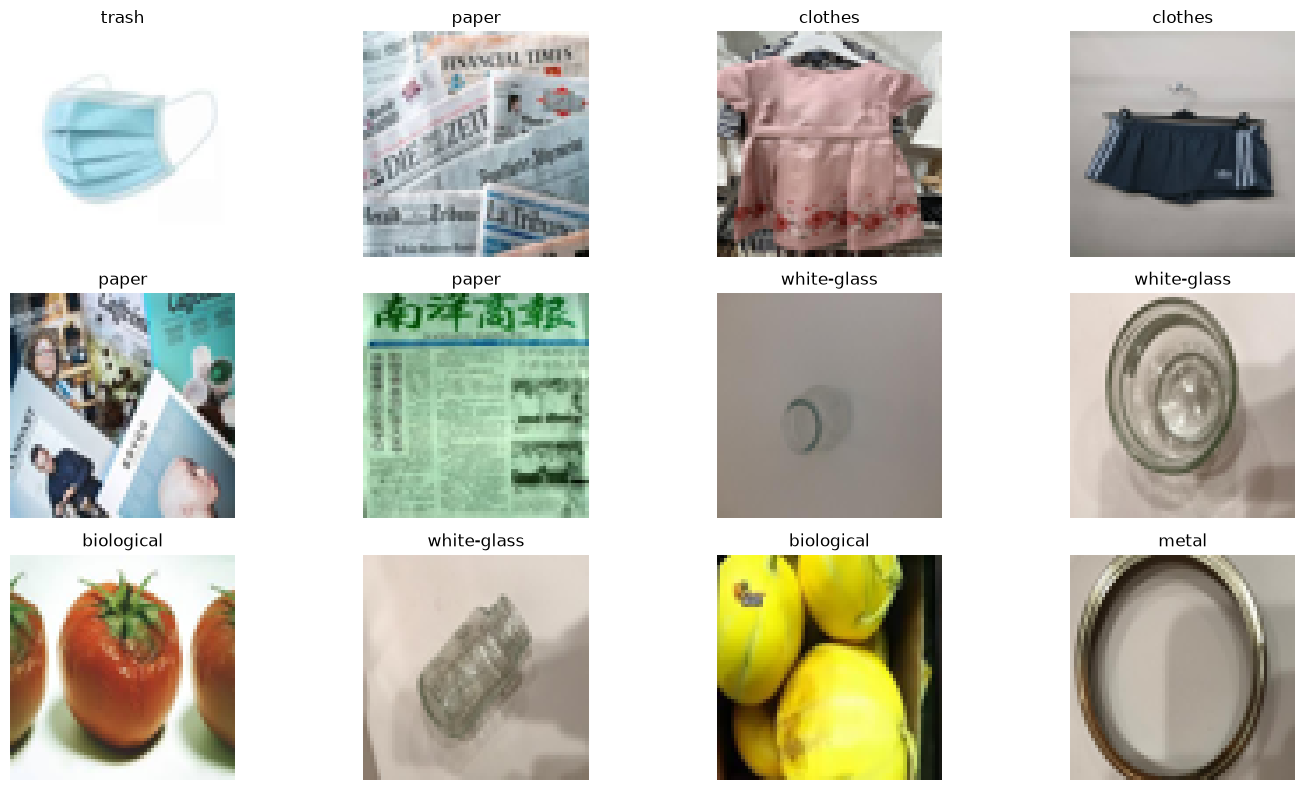


Number of images in each class:
battery: 945
biological: 985
brown-glass: 607
cardboard: 891
clothes: 5325
green-glass: 629
metal: 769
paper: 1050
plastic: 865
shoes: 1977
trash: 697
white-glass: 775

Total images: 15515


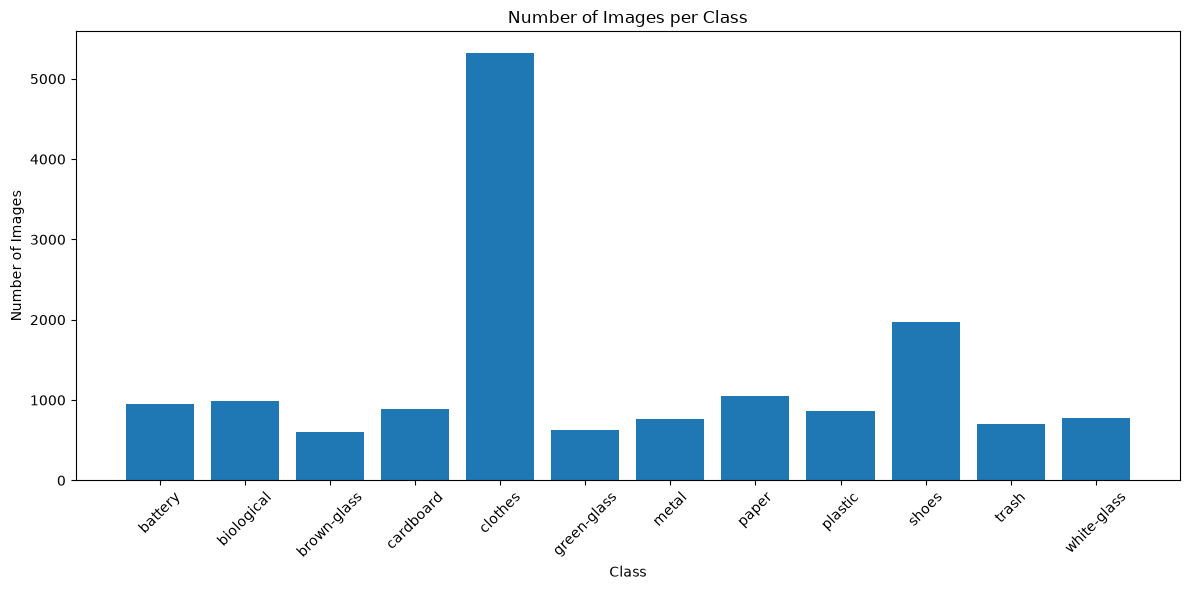

In [5]:
# =========================================
# Explore Data
# =========================================

plt.figure(figsize=(15, 8))

sample_indices = random.sample(
    range(len(images)),
    min(12, len(images))
)

for i, idx in enumerate(sample_indices):

    plt.subplot(3, 4, i + 1)
    plt.imshow(
        images[idx]
    )
    plt.title(
        classes[labels[idx]]
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

class_counts = np.bincount(
    labels,
    minlength=n_classes
)

print("\nNumber of images in each class:")

for i, class_name in enumerate(classes):
    print(
        f"{class_name}: {class_counts[i]}"
    )

print(
    "\nTotal images:",
    len(images)
)

plt.figure(figsize=(12, 6))
plt.bar(
    classes,
    class_counts
)
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.title(
    "Number of Images per Class"
)
plt.xticks(
    rotation=45
)

plt.tight_layout()
plt.show()

## เตรียมข้อมูล (Data Pre-processing)

ส่วนนี้ใช้เตรียมข้อมูลก่อนนำไปสร้างโมเดล โดยปรับค่า Pixel จากช่วง 0–255 ให้อยู่ในช่วง 0–1 และแบ่งข้อมูลออกเป็น Training Set 80% และ Testing Set 20%

ใช้ Stratified Sampling เพื่อรักษาสัดส่วนของแต่ละ Class ให้ใกล้เคียงกันใน Training และ Testing Set

**Output:** ได้ X_train, X_test, y_train และ y_test สำหรับใช้ในการฝึกและทดสอบโมเดล

In [6]:
# =========================================
# Pre-process
# =========================================

images = images.astype(
    "float32"
) / 255.0
X = images
y = labels
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(
    "\nTraining data:",
    X_train.shape
)
print(
    "Testing data:",
    X_test.shape
)


Training data: (12412, 64, 64, 3)
Testing data: (3103, 64, 64, 3)


## ลดมิติข้อมูลด้วย PCA (PCA for K-Means)

ส่วนนี้ใช้ Principal Component Analysis (PCA) เพื่อลดจำนวน Features ของรูปภาพก่อนนำไปทำ K-Means Clustering

การลดมิติช่วยให้ข้อมูลมีจำนวน Features น้อยลงและเหมาะสมกับการทำ Clustering มากขึ้น

**Output:** ได้ข้อมูลรูปภาพที่ถูกลดมิติให้เหลือ 100 Principal Components

In [7]:
# =========================================
# PCA for K-Means
# =========================================

X_train_flat = X_train.reshape(
    X_train.shape[0],
    -1
)
X_test_flat = X_test.reshape(
    X_test.shape[0],
    -1
)

pca = PCA(
    n_components=100,
    random_state=42
)

X_train_pca = pca.fit_transform(
    X_train_flat
)
X_test_pca = pca.transform(
    X_test_flat
)

print(
    "\nPCA training shape:",
    X_train_pca.shape
)
print(
    "PCA testing shape:",
    X_test_pca.shape
)
print(
    "Explained variance:",
    pca.explained_variance_ratio_.sum()
)


PCA training shape: (12412, 100)
PCA testing shape: (3103, 100)
Explained variance: 0.88560486


## Unsupervised Learning - K-Means

ส่วนนี้ใช้ K-Means Clustering เพื่อจัดกลุ่มรูปภาพตามลักษณะของข้อมูล โดยไม่ได้ใช้ Label ของรูปภาพในการจัดกลุ่ม

K-Means ใช้สำหรับการสำรวจข้อมูล (Exploratory Analysis) และเปรียบเทียบกับวิธีการจำแนกแบบ Supervised Learning

**Output:** รูปภาพแต่ละรูปจะถูกกำหนดให้อยู่ใน Cluster ใด Cluster หนึ่ง


K-Means completed.
Number of clusters: 12

Number of samples in each cluster:
Cluster 0: 594
Cluster 1: 1649
Cluster 2: 1374
Cluster 3: 758
Cluster 4: 1126
Cluster 5: 978
Cluster 6: 1007
Cluster 7: 942
Cluster 8: 898
Cluster 9: 1455
Cluster 10: 1127
Cluster 11: 504


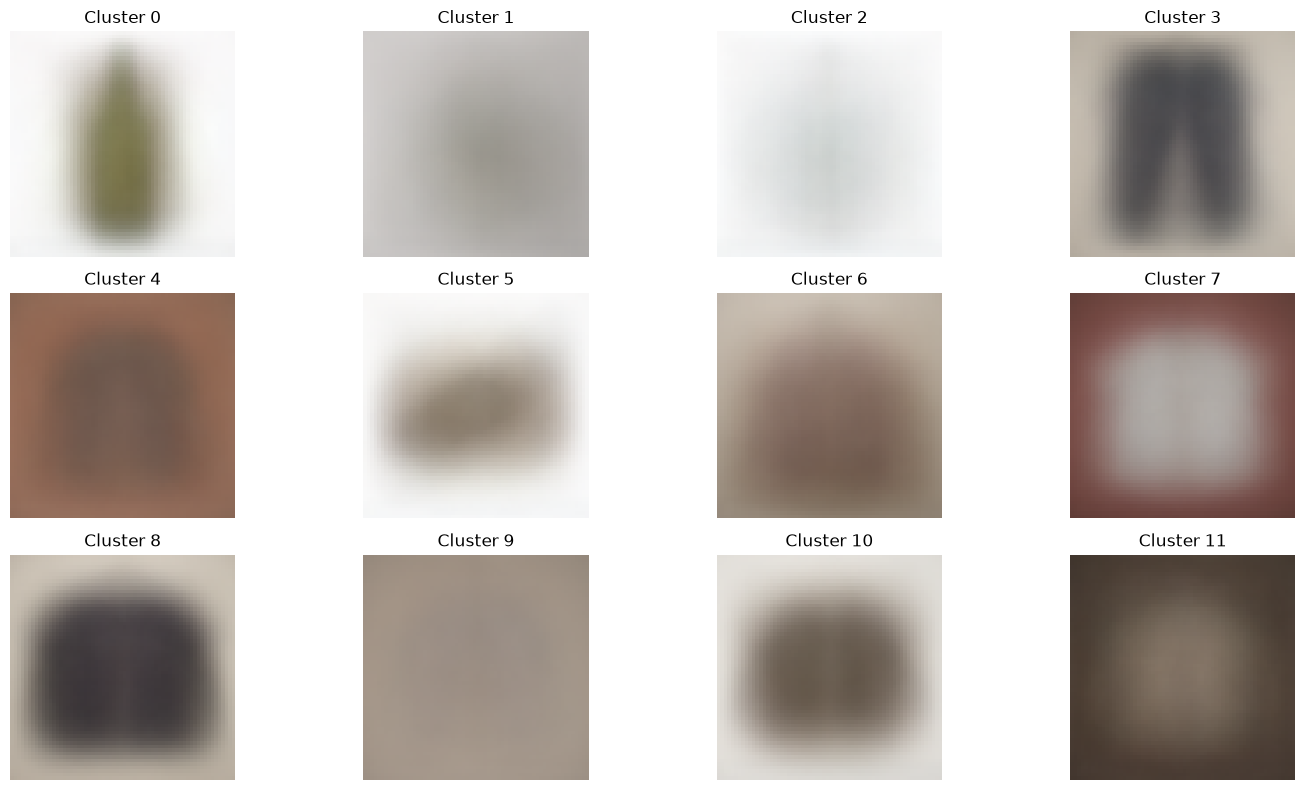

In [8]:
# =========================================
# Unsupervised Learning - K-Means
# =========================================

clf = cluster.KMeans(
    n_clusters=n_classes,
    random_state=42,
    n_init=10
)

clf.fit(
    X_train_pca
)
cluster_labels = clf.labels_

print(
    "\nK-Means completed."
)
print(
    "Number of clusters:",
    n_classes
)
print(
    "\nNumber of samples in each cluster:"
)

for cluster_id in range(n_classes):
    count = np.sum(
        cluster_labels == cluster_id
    )
    print(
        f"Cluster {cluster_id}: {count}"
    )

cluster_centers = pca.inverse_transform(
    clf.cluster_centers_
)

plt.figure(figsize=(15, 8))

for i in range(n_classes):
    center = cluster_centers[i].reshape(
        IMG_SIZE,
        IMG_SIZE,
        3
    )
    plt.subplot(
        3,
        4,
        i + 1
    )
    plt.imshow(
        np.clip(center, 0, 1)
    )
    plt.title(
        f"Cluster {i}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

## Supervised Learning - CNN

ส่วนนี้ใช้สร้าง Convolutional Neural Network (CNN) สำหรับจำแนกรูปภาพขยะตาม Class ที่กำหนดไว้

โมเดลประกอบด้วย Convolutional Layer, Max Pooling, Fully Connected Layer และ Dropout โดยใช้ Softmax ในการทำนาย Class

**Output:** ได้โครงสร้าง CNN Model ที่พร้อมสำหรับการ Training

In [9]:
# =========================================
# Supervised Learning - CNN
# =========================================

print(
    "\nBuilding CNN model..."
)

model = Sequential([
    Conv2D(
        32,
        (3, 3),
        activation="relu",
        input_shape=(
            IMG_SIZE,
            IMG_SIZE,
            3
        )
    ),
    MaxPooling2D(
        (2, 2)
    ),
    Conv2D(
        64,
        (3, 3),
        activation="relu"
    ),
    MaxPooling2D(
        (2, 2)
    ),
    Conv2D(
        128,
        (3, 3),
        activation="relu"
    ),
    MaxPooling2D(
        (2, 2)
    ),
    Flatten(),
    Dense(
        128,
        activation="relu"
    ),
    Dropout(
        0.5
    ),
    Dense(
        n_classes,
        activation="softmax"
    )
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()


Building CNN model...


c:\Users\User\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 12)             │         1,548 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 684,748 (2.61 MB)

 Trainable params: 684,748 (2.61 MB)

 Non-trainable params: 0 (0.00 B)

## ฝึก CNN Model (Train the CNN)

ส่วนนี้ใช้ Training Dataset เพื่อฝึก CNN Model ให้สามารถเรียนรู้ลักษณะของรูปภาพขยะในแต่ละ Class

ใช้ Adam เป็น Optimizer และ Sparse Categorical Cross-Entropy เป็น Loss Function

**Output:** ได้ค่า Training และ Validation Accuracy รวมถึง Loss ในแต่ละ Epoch

In [10]:
# =========================================
# Train CNN
# =========================================

history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/10
311/311 ━━━━━━━━━━━━━━━━━━━━ 30s 81ms/step - accuracy: 0.4461 - loss: 1.6726 - val_accuracy: 0.5602 - val_loss: 1.2886
Epoch 2/10
311/311 ━━━━━━━━━━━━━━━━━━━━ 24s 78ms/step - accuracy: 0.5683 - loss: 1.2949 - val_accuracy: 0.6327 - val_loss: 1.1338
Epoch 3/10
311/311 ━━━━━━━━━━━━━━━━━━━━ 20s 64ms/step - accuracy: 0.6279 - loss: 1.1522 - val_accuracy: 0.6613 - val_loss: 1.0163
Epoch 4/10
311/311 ━━━━━━━━━━━━━━━━━━━━ 18s 59ms/step - accuracy: 0.6567 - loss: 1.0415 - val_accuracy: 0.6935 - val_loss: 0.9244
Epoch 5/10
311/311 ━━━━━━━━━━━━━━━━━━━━ 19s 60ms/step - accuracy: 0.6976 - loss: 0.9308 - val_accuracy: 0.7137 - val_loss: 0.9093
Epoch 6/10
311/311 ━━━━━━━━━━━━━━━━━━━━ 18s 57ms/step - accuracy: 0.7163 - loss: 0.8538 - val_accuracy: 0.7298 - val_loss: 0.8416
Epoch 7/10
311/311 ━━━━━━━━━━━━━━━━━━━━ 24s 76ms/step - accuracy: 0.7483 - loss: 0.7843 - val_accuracy: 0.7318 - val_loss: 0.8387
Epoch 8/10
311/311 ━━━━━━━━━━━━━━━━━━━━ 23s 74ms/step - accuracy: 0.7637 - loss: 0.7021 - 

## ประเมิน CNN Model (Evaluate the CNN)

ส่วนนี้ใช้ Testing Dataset ที่ไม่เคยใช้ในการ Training เพื่อประเมินความสามารถของโมเดลกับข้อมูลที่ไม่เคยเห็นมาก่อน

**Output:** แสดงค่า Test Loss และ Test Accuracy ของ CNN Model

In [11]:
# =========================================
# Evaluate CNN
# =========================================

test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print(
    "\nTest Loss:",
    test_loss
)
print(
    "Test Accuracy:",
    test_accuracy
)

97/97 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.7564 - loss: 0.8200

Test Loss: 0.8200358748435974
Test Accuracy: 0.7563648223876953


## ทำนายผล (Prediction)

ส่วนนี้ใช้ CNN Model ที่ผ่านการฝึกแล้วในการทำนายประเภทของรูปภาพใน Testing Dataset

**Output:** ได้ Class ที่โมเดลทำนายและค่าความน่าจะเป็น (Prediction Probability) ของแต่ละ Class

In [12]:
# =========================================
# Prediction
# =========================================

y_pred_probability = model.predict(
    X_test,
    verbose=0
)

y_pred_cnn = np.argmax(
    y_pred_probability,
    axis=1
)

## Classification Report

ส่วนนี้ใช้ประเมินผลการจำแนกในแต่ละ Class โดยใช้ Precision, Recall และ F1-score

นอกจากนี้ยังแสดงค่า Macro Average และ Weighted Average เพื่อสรุปผลการจำแนกหลาย Class

- Macro Average: ให้น้ำหนักแต่ละ Class เท่ากัน
- Weighted Average: ให้น้ำหนักตามจำนวนข้อมูลของแต่ละ Class

**Output:** ตาราง Classification Report ของแต่ละ Class พร้อมค่า Precision, Recall, F1-score และ Support

In [13]:
# =========================================
# Classification Report
# =========================================

print(
    "\nClassification Report:"
)

print(
    metrics.classification_report(
        y_test,
        y_pred_cnn,
        target_names=classes
    )
)


Classification Report:
              precision    recall  f1-score   support

     battery       0.81      0.67      0.73       189
  biological       0.76      0.62      0.69       197
 brown-glass       0.66      0.75      0.70       122
   cardboard       0.73      0.74      0.73       178
     clothes       0.86      0.95      0.90      1065
 green-glass       0.81      0.91      0.86       126
       metal       0.47      0.51      0.49       154
       paper       0.71      0.56      0.63       210
     plastic       0.58      0.57      0.58       173
       shoes       0.70      0.74      0.72       395
       trash       0.76      0.60      0.67       139
 white-glass       0.66      0.49      0.56       155

    accuracy                           0.76      3103
   macro avg       0.71      0.68      0.69      3103
weighted avg       0.75      0.76      0.75      3103



## Confusion Matrix

ส่วนนี้ใช้ตรวจสอบว่าโมเดลจำแนกแต่ละ Class ได้ถูกต้องหรือเกิดความสับสนระหว่าง Class ใดบ้าง

ค่าบนแนว Diagonal แสดงจำนวนข้อมูลที่ทำนายถูกต้อง ส่วนค่าที่อยู่นอก Diagonal แสดงจำนวนข้อมูลที่ทำนายผิด

**Output:** แสดง Confusion Matrix ในรูปแบบ Heatmap

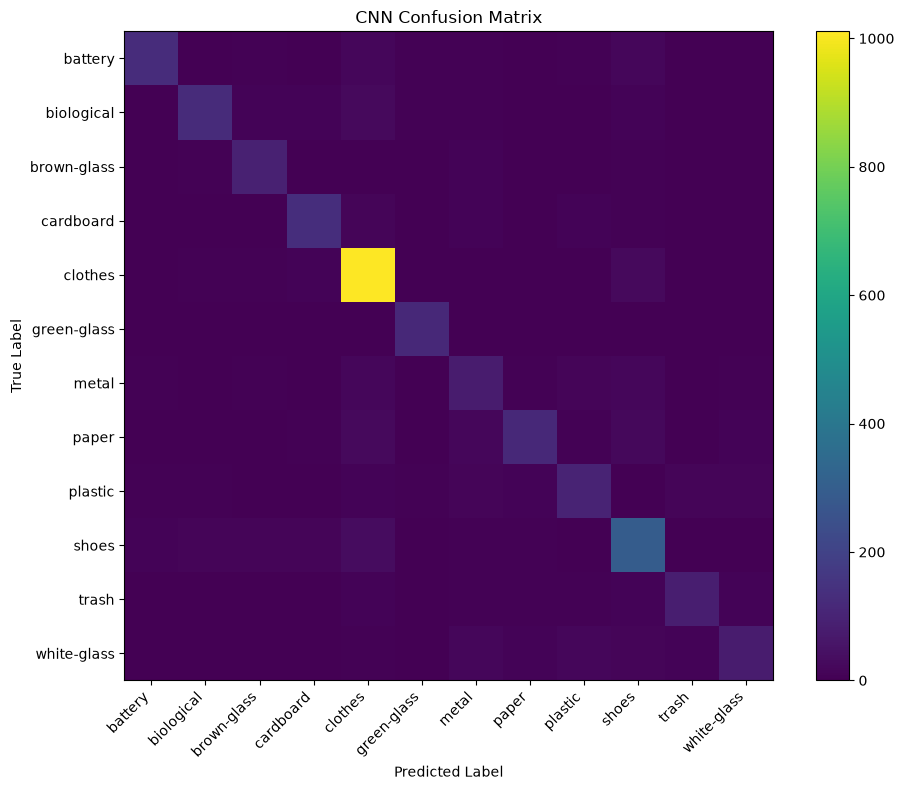

In [14]:
# =========================================
# Confusion Matrix
# =========================================

cm = metrics.confusion_matrix(
    y_test,
    y_pred_cnn
)

plt.figure(
    figsize=(10, 8)
)
plt.imshow(
    cm
)
plt.title(
    "CNN Confusion Matrix"
)
plt.xlabel(
    "Predicted Label"
)
plt.ylabel(
    "True Label"
)
plt.xticks(
    range(n_classes),
    classes,
    rotation=45,
    ha="right"
)
plt.yticks(
    range(n_classes),
    classes
)
plt.colorbar()
plt.tight_layout()
plt.show()

## CNN Accuracy

ส่วนนี้ใช้แสดงค่า Accuracy ของ CNN Model จาก Testing Dataset

Accuracy แสดงสัดส่วนของรูปภาพที่โมเดลสามารถจำแนกได้ถูกต้องจากรูปภาพทั้งหมดใน Test Set

**Output:** แสดงค่า Test Accuracy ของโมเดลในรูปแบบเปอร์เซ็นต์

In [15]:
# =========================================
# CNN Accuracy
# =========================================

accuracy = metrics.accuracy_score(
    y_test,
    y_pred_cnn
)

print(
    "\nCNN Accuracy:",
    accuracy
)


CNN Accuracy: 0.7563648082500806


## Training History

ส่วนนี้ใช้แสดงประวัติการฝึก CNN ในแต่ละ Epoch โดยเปรียบเทียบ Training Accuracy กับ Validation Accuracy และ Training Loss กับ Validation Loss

ใช้เพื่อดูแนวโน้มการเรียนรู้ของโมเดลและตรวจสอบว่ามีแนวโน้มเกิด Overfitting หรือไม่

**Output:** แสดงกราฟ Accuracy และ Loss ของ Training และ Validation

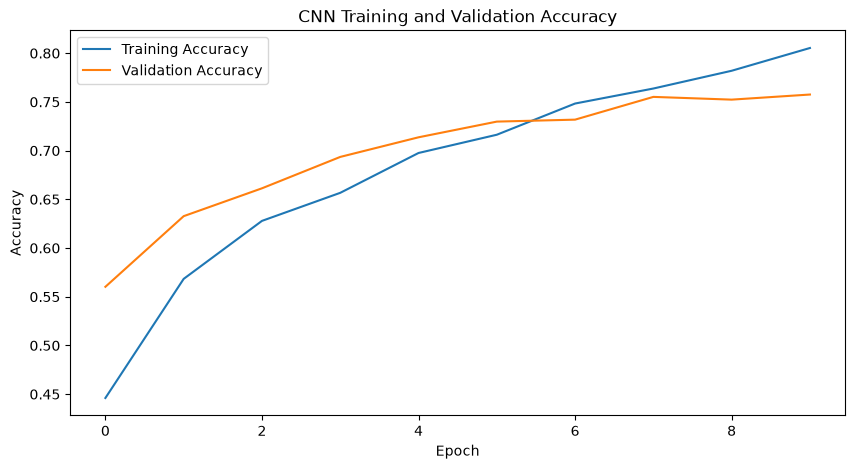

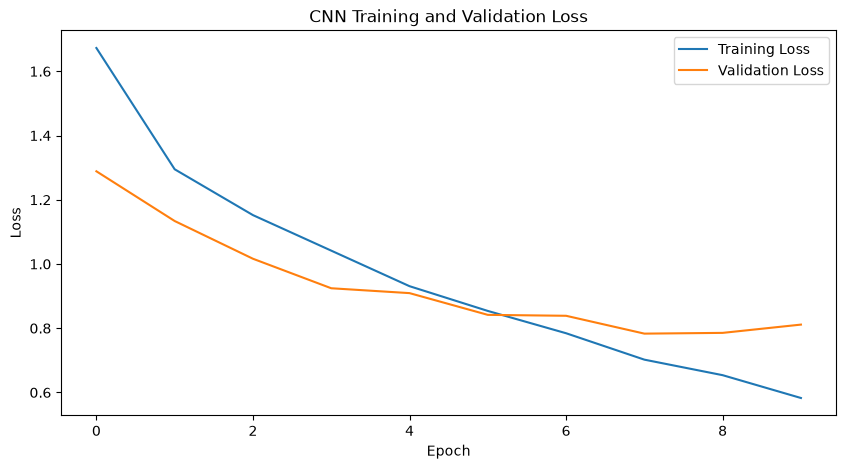

In [16]:
# =========================================
# Training History
# =========================================

plt.figure(
    figsize=(10, 5)
)

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Accuracy"
)

plt.title(
    "CNN Training and Validation Accuracy"
)

plt.legend()
plt.show()

plt.figure(
    figsize=(10, 5)
)

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Loss"
)

plt.title(
    "CNN Training and Validation Loss"
)

plt.legend()
plt.show()

## ทดสอบการทำนายแบบสุ่ม (Random Prediction)

ส่วนนี้สุ่มเลือกรูปภาพจาก Testing Dataset แล้วนำไปให้ CNN Model ทำนายประเภทของขยะ

**Output:** แสดงรูปภาพที่สุ่มเลือก พร้อม Actual Class, Predicted Class และ Confidence

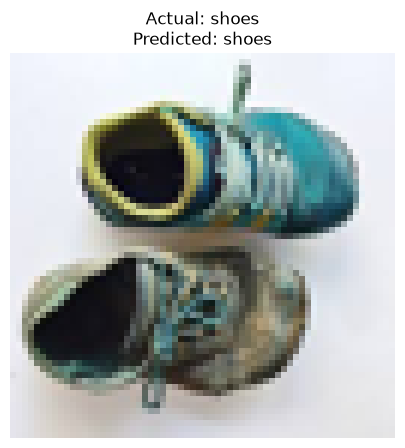


Random Prediction
Actual   : shoes
Predicted: shoes


In [17]:
# =========================================
# Random Prediction
# =========================================

random_index = random.randint(
    0,
    len(X_test) - 1
)

prediction = y_pred_cnn[random_index]
actual = y_test[random_index]

plt.figure(
    figsize=(5, 5)
)

plt.imshow(
    X_test[random_index]
)

plt.title(
    f"Actual: {classes[actual]}\n"
    f"Predicted: {classes[prediction]}"
)

plt.axis("off")
plt.show()

print(
    "\nRandom Prediction"
)

print(
    "Actual   :",
    classes[actual]
)

print(
    "Predicted:",
    classes[prediction]
)

## แสดงผลการทำนาย 12 รูป (Test Predictions)

ส่วนนี้เลือกตัวอย่างรูปภาพจำนวน 12 รูปจาก Testing Dataset เพื่อเปรียบเทียบ Class จริงกับ Class ที่โมเดลทำนาย

**Output:** แสดงรูปภาพ 12 รูป พร้อม Actual Label และ Predicted Label

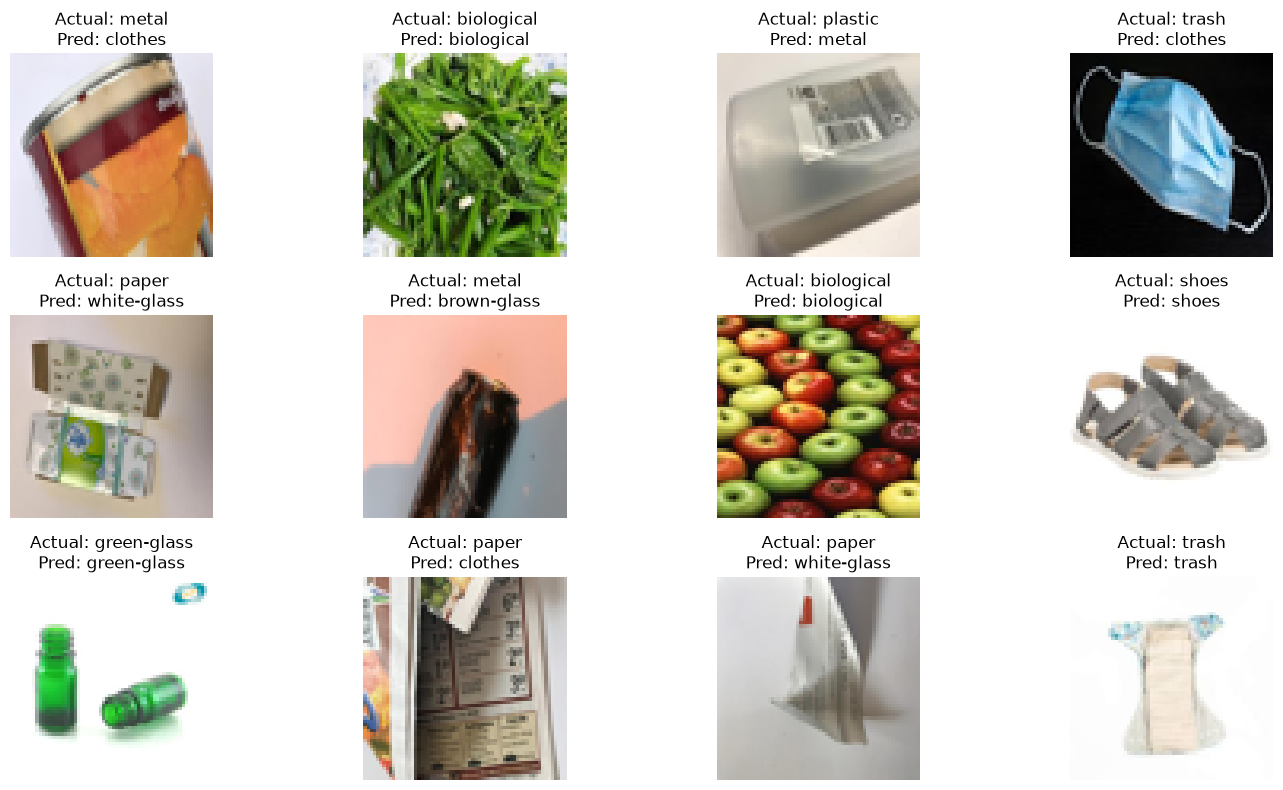

In [18]:
# =========================================
# Show 12 Test Predictions
# =========================================

num_samples = min(
    12,
    len(X_test)
)

sample_indices = random.sample(
    range(len(X_test)),
    num_samples
)

plt.figure(
    figsize=(15, 8)
)

for i, idx in enumerate(sample_indices):
    prediction = y_pred_cnn[idx]
    actual = y_test[idx]

    plt.subplot(
        3,
        4,
        i + 1
    )

    plt.imshow(
        X_test[idx]
    )

    plt.title(
        f"Actual: {classes[actual]}\n"
        f"Pred: {classes[prediction]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

## บันทึกโมเดล (Save Model Artifact)

ส่วนนี้ใช้บันทึก CNN Model ที่ผ่านการ Training แล้ว รวมถึงข้อมูลที่จำเป็น เช่น รายชื่อ Class และขนาดของรูปภาพ

การบันทึกโมเดลช่วยให้สามารถนำโมเดลกลับมาใช้งานได้โดยไม่ต้อง Training ใหม่

**Output:** ได้ไฟล์ Model และ Metadata ที่สามารถนำไปใช้สำหรับการทำนายภายหลัง

In [19]:
# =========================================
# Save Model Artifact
# =========================================

MODEL_PATH = "trash_class_cnn_mvp.keras"
ARTIFACT_PATH = "trash_class_cnn_mvp.joblib"
model.save(
    MODEL_PATH
)

model_package = {
    "model_path": MODEL_PATH,
    "classes": classes,
    "image_size": IMG_SIZE
}

joblib.dump(
    model_package,
    ARTIFACT_PATH
)

print(
    "\nSaved:",
    MODEL_PATH
)

print(
    "Saved:",
    ARTIFACT_PATH
)


Saved: trash_class_cnn_mvp.keras
Saved: trash_class_cnn_mvp.joblib


## โหลดโมเดล (Load Model Artifact)

ส่วนนี้ใช้โหลด CNN Model ที่บันทึกไว้กลับมาใช้งาน และตรวจสอบว่าสามารถนำโมเดลที่บันทึกไว้มาใช้ได้โดยไม่ต้อง Training ใหม่

**Output:** CNN Model ที่บันทึกไว้ถูกโหลดกลับเข้าสู่โปรแกรมสำเร็จ

In [20]:
# =========================================
# Load Model Artifact
# =========================================

artifact = joblib.load(
    ARTIFACT_PATH
)

loaded_model = tf.keras.models.load_model(
    artifact["model_path"]
)

loaded_classes = artifact["classes"]
loaded_img_size = artifact["image_size"]

print(
    "\nLoaded classes:",
    loaded_classes
)

print(
    "Loaded image size:",
    loaded_img_size
)


Loaded classes: ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']
Loaded image size: 64


## สร้างฟังก์ชันสำหรับทำนาย (Build an Inference Function)

ส่วนนี้สร้างฟังก์ชันสำหรับรับรูปภาพใหม่ แล้วทำ Pre-processing แบบเดียวกับตอน Training ก่อนนำเข้า CNN Model

ฟังก์ชันจะทำนายประเภทขยะและคำนวณ Confidence ของผลการทำนาย

**Output:** ได้ฟังก์ชันที่สามารถรับรูปภาพและคืนค่า Predicted Class และ Confidence Score

In [21]:
# =========================================
# Build an Inference Function
# =========================================

def predict_trash(image):
    image = image.convert(
        "RGB"
    )
    image = image.resize(
        (
            loaded_img_size,
            loaded_img_size
        )
    )
    image_array = np.array(
        image
    ).astype(
        "float32"
    ) / 255.0

    image_array = np.expand_dims(
        image_array,
        axis=0
    )

    probabilities = loaded_model.predict(
        image_array,
        verbose=0
    )[0]
    predicted_index = np.argmax(
        probabilities
    )
    predicted_class = loaded_classes[
        predicted_index
    ]
    confidence = probabilities[
        predicted_index
    ]
    return {
        predicted_class:
        float(confidence)
    }

## ทดสอบ Inference Function

ส่วนนี้ใช้ทดสอบฟังก์ชัน Inference ด้วยรูปภาพตัวอย่าง เพื่อให้แน่ใจว่าสามารถรับรูปภาพและทำนายผลได้ถูกต้อง

**Output:** แสดงประเภทขยะที่โมเดลทำนายและค่า Confidence Score

In [22]:
# =========================================
# Test Inference
# =========================================

sample_index = 0
sample_image = Image.fromarray(
    (
        X_test[sample_index] * 255
    ).astype(
        "uint8"
    )
)

prediction = predict_trash(
    sample_image
)

print(
    "\nPrediction:",
    prediction
)

print(
    "Actual:",
    classes[
        y_test[sample_index]
    ]
)


Prediction: {'shoes': 0.762172520160675}
Actual: shoes


## สร้าง Web Application ด้วย Gradio

ส่วนนี้เตรียมฟังก์ชันสำหรับนำ CNN Model ไปใช้งานผ่าน Gradio Web Interface

ผู้ใช้สามารถ Upload รูปภาพขยะและให้โมเดลทำนายประเภทของขยะได้

**Output:** เตรียม Components ที่จำเป็นสำหรับสร้าง Web Application

In [23]:
# =========================================
# Part F — Build the Web UI with Gradio
# =========================================

# Overall model accuracy
model_accuracy = accuracy * 100
def predict_trash_web(image, actual_class):
    if image is None:
        return (
            {},
            "⚠️ Please upload an image.",
            "No image",
            ""
        )
    # Convert image to RGB
    image = image.convert("RGB")
    # Resize image
    image = image.resize(
        (loaded_img_size, loaded_img_size)
    )
    # Convert image to numpy
    image_array = np.array(
        image
    ).astype(
        "float32"
    ) / 255.0
    # Add batch dimension
    image_array = np.expand_dims(
        image_array,
        axis=0
    )
    # Predict
    probabilities = loaded_model.predict(
        image_array,
        verbose=0
    )[0]
    # Sort predictions
    sorted_indices = np.argsort(
        probabilities
    )[::-1]
    # Top 5 predictions
    top_predictions = {
        loaded_classes[i]: float(probabilities[i])
        for i in sorted_indices[:5]
    }
    # Best prediction
    predicted_index = sorted_indices[0]
    predicted_class = loaded_classes[
        predicted_index
    ]
    confidence = probabilities[
        predicted_index
    ] * 100
    # Check correctness
    if actual_class is None:
        status = """
        <div class="status-box neutral">
            <div class="status-icon">🔍</div>
            <div>
                <div class="status-title">
                    ยังไม่ได้ตรวจสอบ
                </div>
                <div class="status-text">
                    เลือก Actual Class เพื่อดูว่าผลทำนายถูกหรือผิด
                </div>
            </div>
        </div>
        """
    elif predicted_class == actual_class:
        status = f"""
        <div class="status-box correct">
            <div class="status-icon">✓</div>
            <div>
                <div class="status-title">
                    ถูกต้อง!
                </div>
                <div class="status-text">
                    Actual: <b>{actual_class}</b>
                    &nbsp; | &nbsp;
                    Predicted: <b>{predicted_class}</b>
                </div>
            </div>
        </div>
        """
    else:
        status = f"""
        <div class="status-box wrong">
            <div class="status-icon">✗</div>
            <div>
                <div class="status-title">
                    ทำนายผิด
                </div>
                <div class="status-text">
                    Actual: <b>{actual_class}</b>
                    &nbsp; | &nbsp;
                    Predicted: <b>{predicted_class}</b>
                </div>
            </div>
        """
    prediction_text = f"""
    <div class="prediction-card">
        <div class="prediction-label">
            PREDICTION
        </div>
        <div class="prediction-class">
            {predicted_class}
        </div>
        <div class="confidence-text">
            Confidence: <b>{confidence:.2f}%</b>
        </div>
    </div>
    """
    return (
        top_predictions,
        status,
        prediction_text,
        f"{confidence:.2f}%"
    )

In [24]:
# =========================================
# Custom CSS
# =========================================

custom_css = """

body {
    background:
        linear-gradient(
            135deg,
            #eaf7ff 0%,
            #f8f0ff 50%,
            #fff0f7 100%
        ) !important;
}


.gradio-container {
    max-width: 1100px !important;
    margin: auto !important;
    background: transparent !important;
}


/* Main Header */

.main-header {
    text-align: center;
    padding: 28px 20px 20px 20px;
}


.main-title {
    font-size: 38px;
    font-weight: 800;
    background:
        linear-gradient(
            90deg,
            #5baee8,
            #c58bea,
            #ef8fba
        );
    -webkit-background-clip: text;
    -webkit-text-fill-color: transparent;
    margin-bottom: 8px;
}

.main-subtitle {
    color: #6d7180;
    font-size: 16px;
}

/* Statistics */

.stats-container {
    display: flex;
    justify-content: center;
    gap: 18px;
    margin: 10px 0 25px 0;
}


.stat-card {
    background: rgba(255,255,255,0.75);
    border: 1px solid rgba(255,255,255,0.9);
    border-radius: 18px;
    padding: 18px 30px;
    min-width: 180px;
    text-align: center;
    box-shadow: 0 8px 25px rgba(120,150,190,0.12);
}


.stat-number {
    font-size: 28px;
    font-weight: 800;
    color: #6b9fd0;
}


.stat-label {
    color: #777b88;
    font-size: 13px;
    margin-top: 3px;
}


/* Cards */

.panel {
    background: rgba(255,255,255,0.82);
    border-radius: 22px;
    padding: 22px;
    border: 1px solid rgba(255,255,255,0.9);
    box-shadow: 0 10px 30px rgba(120,150,190,0.12);
}


/* Prediction */

.prediction-card {
    background:
        linear-gradient(
            135deg,
            #e5f5ff,
            #f8eaff
        );
    border-radius: 20px;
    padding: 25px;
    text-align: center;
    margin-top: 12px;
    border: 1px solid #e2d8f7;
}


.prediction-label {
    font-size: 12px;
    letter-spacing: 2px;
    color: #8a8fa0;
}


.prediction-class {
    font-size: 32px;
    font-weight: 800;
    color: #668fbe;
    margin: 8px 0;
}


.confidence-text {
    font-size: 15px;
    color: #777b88;
}


/* Correct */

.status-box {
    display: flex;
    align-items: center;
    gap: 15px;
    padding: 18px 22px;
    border-radius: 18px;
    margin: 12px 0;
}


.status-box.correct {
    background: #e8f9f1;
    border: 1px solid #bcebd6;
}


.status-box.wrong {
    background: #fff0f4;
    border: 1px solid #f4c4d3;
}


.status-box.neutral {
    background: #eef7ff;
    border: 1px solid #cbe4f7;
}


.status-icon {
    font-size: 30px;
    font-weight: 800;
}


.correct .status-icon {
    color: #55b98b;
}


.wrong .status-icon {
    color: #e984a2;
}


.neutral .status-icon {
    color: #6caad8;
}


.status-title {
    font-size: 20px;
    font-weight: 750;
    color: #606575;
}


.status-text {
    color: #777b88;
    margin-top: 3px;
}


/* Buttons */

button {
    border-radius: 12px !important;
}


/* Footer */

.footer {
    text-align: center;
    color: #9a9daa;
    font-size: 13px;
    padding: 25px;
}

"""

In [25]:
# =========================================
# Gradio Interface
# =========================================

with gr.Blocks(
    css=custom_css,
    title="Garbage Classification — CNN"
) as app:
    # Header
    gr.HTML(
        """
        <div class="main-header">

            <div class="main-title">
                ♻️ Garbage Classification
            </div>

            <div class="main-subtitle">
                CNN Image Classification System
            </div>

        </div>
        """
    )


    # Model Statistics
    gr.HTML(
        f"""
        <div class="stats-container">

            <div class="stat-card">
                <div class="stat-number">
                    {model_accuracy:.2f}%
                </div>

                <div class="stat-label">
                    Test Accuracy
                </div>
            </div>


            <div class="stat-card">
                <div class="stat-number">
                    {n_classes}
                </div>

                <div class="stat-label">
                    Garbage Classes
                </div>
            </div>


            <div class="stat-card">
                <div class="stat-number">
                    {IMG_SIZE}×{IMG_SIZE}
                </div>

                <div class="stat-label">
                    Input Image Size
                </div>
            </div>

        </div>
        """
    )


    with gr.Row():

        # =================================
        # Left Side
        # =================================

        with gr.Column(
            scale=1,
            elem_classes="panel"
        ):

            gr.Markdown(
                "### 🩵 Upload Image"
            )

            image_input = gr.Image(
                type="pil",
                label="Garbage Image"
            )


            actual_class = gr.Dropdown(

                choices=classes,

                label="Actual Class (สำหรับตรวจว่าถูก/ผิด)",

                info=(
                    "ถ้ารู้ class จริง ให้เลือก "
                    "เพื่อเปรียบเทียบกับผลทำนาย"
                ),

                value=None

            )


            predict_button = gr.Button(
                "🔍 Predict",
                variant="primary"
            )


        # =================================
        # Right Side
        # =================================

        with gr.Column(
            scale=1,
            elem_classes="panel"
        ):

            gr.Markdown(
                "### 🌸 Prediction Result"
            )


            prediction_output = gr.Label(
                label="Top 5 Predictions",
                num_top_classes=5
            )


            status_output = gr.HTML()


            prediction_detail = gr.HTML()


            confidence_output = gr.Textbox(
                label="Top Prediction Confidence",
                interactive=False
            )


    # =================================
    # Information
    # =================================

    gr.Markdown(
        """
        ### 📊 Model Information

        **Model:** Convolutional Neural Network (CNN)

        **Classes:** battery, biological, brown-glass, cardboard,
        clothes, green-glass, metal, paper, plastic, shoes,
        trash, white-glass

        **Image Size:** 64 × 64 pixels

        **Test Accuracy:** Accuracy calculated from the CNN test set.

        > Actual Class ต้องเลือกเองเพื่อใช้ตรวจสอบว่า prediction
        > ของรูปนั้นถูกหรือผิด
        """
    )


    gr.HTML(
        """
        <div class="footer">
            ♻️ Garbage Classification CNN · Machine Learning Project
        </div>
        """
    )


    # =================================
    # Prediction Event
    # =================================

    predict_button.click(

        fn=predict_trash_web,

        inputs=[
            image_input,
            actual_class
        ],

        outputs=[
            prediction_output,
            status_output,
            prediction_detail,
            confidence_output
        ]

    )

C:\Users\User\AppData\Local\Temp\ipykernel_32384\3234145203.py:5: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: css. Please pass these parameters to launch() instead.
  with gr.Blocks(


In [26]:
# =========================================
# Launch
# =========================================

app.launch()

* Running on local URL:  http://127.0.0.1:7863
* To create a public link, set `share=True` in `launch()`.
